# Multi-Modal Plant Disease Dataset: Selection, Description and Analysis
## PlantVillage leaf images paired with symptom text and agronomic metadata

*COMP6001 - Computer Vision and Multimodal Machine Learning - Final Project*

## Section 1 - Objective of this Notebook

Crop diseases reduce yield and threaten food security, and identifying a disease early is a key step in managing it. This project builds an automatic leaf-disease classifier. Before any model is trained, the data itself must be understood, because the quality, balance and structure of a dataset limit what any model can learn.

This notebook therefore does five things:

1. explains the core ideas of computer vision and multi-modal machine learning that the dataset is chosen for (Section 2);
2. describes the chosen dataset, its three modalities and its properties (Sections 3 - 7);
3. creates a reproducible train / validation / test split (Section 8);
4. visualises the dataset (Sections 9 - 10);
5. analyses class distributions, image feature distributions, the text modality and the relationship between modalities (Sections 9 - 13).

## Section 2 - Background: Computer Vision and Multi-Modal Machine Learning

**Computer vision** is the field that lets computers extract information from images. In *image classification* a model $f_\theta$ maps an image $x \in \mathbb{R}^{H\times W\times 3}$ to a probability for each of $K$ classes:

$$
p_c(x) = \frac{e^{z_c(x)}}{\sum_{j=1}^{K} e^{z_j(x)}}, \qquad \hat{y} = \arg\max_c \, p_c(x),
$$

where $z(x)$ are the raw scores (logits) produced by the model. Two families of methods are used in this project:

* **hand-crafted features** (colour histograms, Histogram of Oriented Gradients) fed to a classical classifier such as an SVM or random forest;
* **deep convolutional neural networks (CNNs)**, which learn the features themselves, from edges and textures in early layers to lesion shapes in deeper layers.

**Multi-modal machine learning** uses data from more than one *modality* (type of data), for example image, text, audio or tabular measurements. For a sample with $M$ modalities $x^{(1)},\dots,x^{(M)}$ there are three common ways to combine them:

$$
\text{early fusion: } \hat{y} = g\big([\phi_1(x^{(1)});\,\phi_2(x^{(2)})]\big), \qquad
\text{late fusion: } \hat{y} = \sum_{m=1}^{M} w_m\, g_m\big(\phi_m(x^{(m)})\big),
$$

$$
\text{joint embedding: } s(x^{(1)},x^{(2)}) = \frac{\phi_1(x^{(1)})\cdot\phi_2(x^{(2)})}{\lVert\phi_1(x^{(1)})\rVert\,\lVert\phi_2(x^{(2)})\rVert},
$$

where $\phi_m$ is an encoder for modality $m$ and $g$ a classifier. Different modalities carry complementary information: an image shows *how a leaf looks*, while text can describe *what the symptoms mean* and metadata gives *context* such as the crop species.

**Applications.** Computer vision is used in medical imaging, autonomous driving, quality inspection and precision agriculture. Multi-modal learning is used in image captioning, visual question answering, matching radiology images with reports, and in agriculture to combine leaf photos with weather data or expert advice. A phone app that classifies a leaf photo and explains the diagnosis in text is a direct example of the system this dataset supports.

## Section 3 - Dataset Choice and Description

**Image modality - PlantVillage.** The PlantVillage dataset (Hughes and Salathe, 2015) is an open-access collection of leaf photographs created to support research on automated plant-disease diagnosis. The full collection holds **54,306 RGB images of 14 crop species in 38 crop-disease classes**, photographed on a plain background under controlled conditions. It was used for the deep-learning study of Mohanty et al. (2016).

**Subset used here.** We keep three crops with clear healthy-versus-diseased classes: **Tomato (10 classes), Potato (3) and Apple (4)**, i.e. **17 classes and 23,483 images**. This keeps the problem a genuine multi-class task while remaining small enough to train on a laptop.

**Why this dataset.** It is large, publicly available, labelled by experts and already used as a benchmark, so results can be compared with published work. Its classes are visually subtle (several different diseases produce brown spots), which makes the classification problem non-trivial.

**Making it multi-modal.** The photographs alone are a single modality. Each image is therefore paired with two further modalities:

| Modality | Type | Content | Source |
|---|---|---|---|
| Image | unstructured | 256 x 256 RGB leaf photograph | PlantVillage |
| Text | unstructured | one- to two-sentence description of the visual symptoms of the class | written for this project from standard plant-pathology descriptions |
| Metadata | tabular / categorical | crop species, cause type (fungus, bacterium, virus, ...), pathogen name | pathogen names taken from Figure 1 of Mohanty et al. (2016); cause type from pathology |

**Important limitation, stated openly.** The text and metadata are attached at *class level* (every image of a class shares the same description); they are not per-image captions. Two consequences follow. First, if the symptom text were fed to a classifier as an input it would reveal the label, so in later notebooks the text is used as a *class description / prototype* (for example to align image and text embeddings), not as a secret input. Second, the text modality contains no information that varies between images of one class.

## Section 4 - Install and Import Libraries

The cell below imports the libraries used for data handling (`pandas`, `numpy`), image reading (`PIL`), statistics (`scipy`, `scikit-learn`) and plotting (`matplotlib`). It also fixes the random seed so the split and the image samples are reproducible. If a package is missing, uncomment the `%pip` line first.

In [1]:
# %pip install pandas numpy scipy scikit-learn matplotlib pillow

import warnings
warnings.filterwarnings("ignore")

import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
np.random.seed(SEED)

Next we define where files live. The notebook works whether Jupyter starts in the repository root or in the `notebooks/` folder: data goes to `data/`, figures and tables go to `results/dataset_analysis/`. The small helper `save_show` saves each figure as a PNG and then displays it. The plotting style is kept plain (default colours, light grid).

In [2]:
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT_DIR / "data"
RESULTS = ROOT_DIR / "results" / "dataset_analysis"
RESULTS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_show(name):
    plt.tight_layout()
    plt.savefig(RESULTS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Repository root:", ROOT_DIR)

Repository root: /Users/sabyasachi/plant_disease_based_classification


## Section 5 - Obtain the Image Data

The full repository contains three versions of every image (colour, grayscale and segmented) and is several gigabytes. We only need the colour images of the chosen crops, so the next cell uses a **git sparse checkout**, which downloads just those folders. Requirement: `git` version 2.25 or newer.

The configuration cell lists the 17 class folders. To test the notebook quickly you can change `CROPS` to `["Potato"]`.

In [3]:
CROPS = ["Tomato", "Potato", "Apple"]
VARIANT = "color"            # the repository also has 'grayscale' and 'segmented'
IMG_DIR = DATA_DIR / "plantvillage"
REPO = "https://github.com/digitalepidemiologylab/plantvillage_deeplearning_paper_dataset.git"

FOLDERS = {
    "Tomato": ["Bacterial_spot", "Early_blight", "Late_blight", "Leaf_Mold", "Septoria_leaf_spot",
               "Spider_mites Two-spotted_spider_mite", "Target_Spot", "Tomato_Yellow_Leaf_Curl_Virus",
               "Tomato_mosaic_virus", "healthy"],
    "Potato": ["Early_blight", "Late_blight", "healthy"],
    "Apple": ["Apple_scab", "Black_rot", "Cedar_apple_rust", "healthy"],
}
wanted = [f"{c}___{d}" for c in CROPS for d in FOLDERS[c]]
print(len(wanted), "class folders requested")

17 class folders requested


The download cell is skipped automatically if the folders already exist, so re-running the notebook is safe. Images that are moved out of the temporary clone end up in `data/plantvillage/<class folder>/`.

In [4]:
def download_images():
    tmp = Path("_pv_tmp")
    if tmp.exists():
        shutil.rmtree(tmp)
    subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", REPO, str(tmp)], check=True)
    folders = [f"raw/{VARIANT}/{w}" for w in wanted]
    subprocess.run(["git", "sparse-checkout", "set", "--no-cone", *[f"/{f}/" for f in folders]], cwd=tmp, check=True)
    IMG_DIR.mkdir(parents=True, exist_ok=True)
    for f in folders:
        src = tmp / f
        if src.exists():
            shutil.move(str(src), str(IMG_DIR / src.name))
        else:
            print("MISSING:", f)
    shutil.rmtree(tmp, ignore_errors=True)

if all((IMG_DIR / w).exists() for w in wanted):
    print("Images already present - skipping download.")
else:
    download_images()

Images already present - skipping download.


A quick verification: count the files in each class folder and make sure no folder is missing or empty.

In [5]:
counts = pd.DataFrame([(w, len(list((IMG_DIR / w).glob("*")))) for w in wanted], columns=["class_folder", "images"])
display(counts)
print(f"Total: {counts['images'].sum():,} images in {len(counts)} classes")
assert (counts["images"] > 0).all(), "Some class folders are empty - delete data/plantvillage and re-run."

,class_folder,images
0,Tomato___Bacterial_spot,2127
1,Tomato___Early_blight,1000
2,Tomato___Late_blight,1909
3,Tomato___Leaf_Mold,952
4,Tomato___Septoria_leaf_spot,1771
5,Tomato___Spider_mites Two-spotted_spider_mite,1676
6,Tomato___Target_Spot,1404
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,5357
8,Tomato___Tomato_mosaic_virus,373
9,Tomato___healthy,1591


Total: 23,483 images in 17 classes


## Section 6 - Build the Multi-Modal Dataset

Here the three modalities are joined into one table with one row per image. The next cell defines the class-level knowledge: for each class, the **cause type**, the **pathogen** and a **symptom description**. Pathogen names follow Figure 1 of Mohanty et al. (2016). The text describes what a person would see on the leaf.

In [6]:
KNOWLEDGE = {
 "Apple - Apple scab": [
  "fungus",
  "Venturia inaequalis",
  "Olive-green to dark brown velvety spots on the leaf surface that later turn rough and scabby. Badly infected leaves turn yellow and drop early."
 ],
 "Apple - Black rot": [
  "fungus",
  "Botryosphaeria obtusa",
  "Circular frog-eye leaf spots with a tan or brown centre and a darker purple border. Spots enlarge and the leaf may yellow around them."
 ],
 "Apple - Cedar apple rust": [
  "fungus",
  "Gymnosporangium juniperi-virginianae",
  "Bright yellow to orange circular spots on the upper leaf surface, often with a reddish border. Small tube-like structures may form on the underside."
 ],
 "Apple - healthy": [
  "none",
  "none (healthy)",
  "Uniformly green leaf with a smooth surface, regular edges and no spots, lesions or discolouration."
 ],
 "Potato - Early blight": [
  "fungus",
  "Alternaria solani",
  "Dark brown spots with concentric rings that look like a target, mostly on older lower leaves. A yellow halo often surrounds each lesion."
 ],
 "Potato - Late blight": [
  "oomycete",
  "Phytophthora infestans",
  "Large irregular water-soaked patches that turn dark brown or black, often with a pale green edge. White mould can appear on the underside in humid weather."
 ],
 "Potato - healthy": [
  "none",
  "none (healthy)",
  "Uniformly green leaf with a smooth surface and no spots, lesions or discolouration."
 ],
 "Tomato - Bacterial spot": [
  "bacterium",
  "Xanthomonas campestris pv. vesicatoria",
  "Many small dark water-soaked spots that turn brown or black, often with a thin yellow halo. Heavily infected leaves look speckled and may drop."
 ],
 "Tomato - Early blight": [
  "fungus",
  "Alternaria solani",
  "Brown spots with concentric rings like a target on older leaves. The tissue around the spots turns yellow and the leaf may die."
 ],
 "Tomato - Late blight": [
  "oomycete",
  "Phytophthora infestans",
  "Large greasy water-soaked dark patches that spread quickly across the leaf. White fuzzy growth can appear on the underside in humid conditions."
 ],
 "Tomato - Leaf Mold": [
  "fungus",
  "Passalora fulva",
  "Pale green or yellow spots on the upper surface of the leaf. An olive-green to brown velvety mould grows on the underside below each spot."
 ],
 "Tomato - Septoria leaf spot": [
  "fungus",
  "Septoria lycopersici",
  "Numerous small circular spots with dark brown borders and grey-white centres, with tiny black dots inside. Lower leaves yellow and fall."
 ],
 "Tomato - Spider mites": [
  "mite",
  "Tetranychus urticae",
  "Fine yellow or white stippling across the leaf surface that gives a bronzed look. Fine webbing may be visible when the attack is severe."
 ],
 "Tomato - Target Spot": [
  "fungus",
  "Corynespora cassiicola",
  "Brown circular lesions with concentric rings and a yellow halo. Lesions may merge and leave holes as the dead tissue falls out."
 ],
 "Tomato - Tomato Yellow Leaf Curl Virus": [
  "virus",
  "Tomato yellow leaf curl virus",
  "Leaves curl upward and turn yellow at the edges and become small and crumpled. The plant is stunted with very little new growth."
 ],
 "Tomato - Tomato mosaic virus": [
  "virus",
  "Tomato mosaic virus",
  "Mottled mosaic of light and dark green patches on the leaf. Leaves can become narrow, curled or distorted."
 ],
 "Tomato - healthy": [
  "none",
  "none (healthy)",
  "Uniformly green leaf with a smooth surface and no spots, lesions or discolouration."
 ]
}

Folder names such as `Tomato___Spider_mites Two-spotted_spider_mite` are awkward, so they are cleaned into readable labels (`Tomato - Spider mites`). Then every image gets:

* `path` - the image file (**image modality**);
* `crop`, `cause_type`, `pathogen` - **tabular modality**;
* `symptom_text` - **text modality**;
* `label` - an integer class id used by the models.

In [7]:
def clean_name(folder):
    crop, cond = folder.split("___")
    cond = cond.replace("Two-spotted_spider_mite", "").replace("_", " ").strip()
    return crop, cond

rows = []
for d in sorted(p for p in IMG_DIR.iterdir() if p.is_dir()):
    crop, cond = clean_name(d.name)
    cname = f"{crop} - {cond}"
    cause, pathogen, text = KNOWLEDGE[cname]
    for f in d.iterdir():
        if f.suffix.lower() in {".jpg", ".jpeg", ".png"}:
            rows.append((str(f), crop, cond, cname, cause, pathogen, text))

df = pd.DataFrame(rows, columns=["path", "crop", "condition", "class_name", "cause_type", "pathogen", "symptom_text"])
df["label"] = df["class_name"].astype("category").cat.codes
df["is_healthy"] = df["condition"].str.lower().eq("healthy")

class_names = df.drop_duplicates("label").sort_values("label")["class_name"].tolist()
print(f"{len(df):,} samples | {df['label'].nunique()} classes | {df['crop'].nunique()} crops")
display(df.drop(columns=["path"]).head(3))

23,483 samples | 17 classes | 3 crops


,crop,condition,class_name,cause_type,pathogen,symptom_text,label,is_healthy
0,Apple,Apple scab,Apple - Apple scab,fungus,Venturia inaequalis,Olive-green to dark brown velvety spots on the...,0,False
1,Apple,Apple scab,Apple - Apple scab,fungus,Venturia inaequalis,Olive-green to dark brown velvety spots on the...,0,False
2,Apple,Apple scab,Apple - Apple scab,fungus,Venturia inaequalis,Olive-green to dark brown velvety spots on the...,0,False


To make the multi-modal structure concrete, the next cell displays one complete sample: the image on the left and its paired text and metadata on the right.

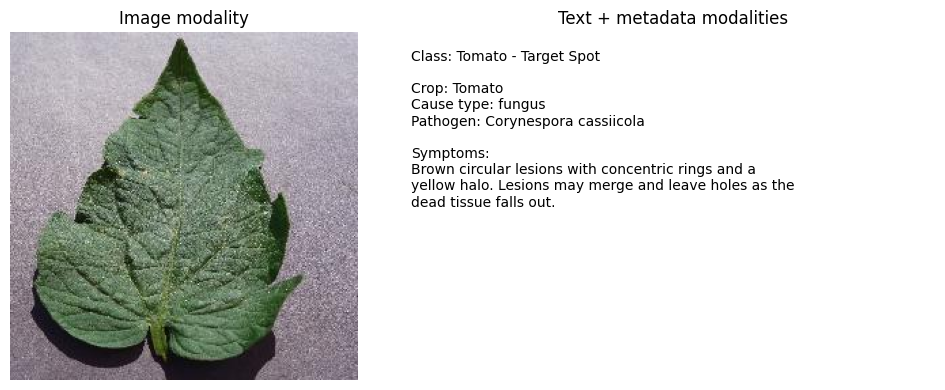

In [8]:
row = df.sample(1, random_state=7).iloc[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.2]})
ax[0].imshow(Image.open(row["path"]).convert("RGB"))
ax[0].axis("off")
ax[0].set_title("Image modality")
ax[1].axis("off")
ax[1].set_title("Text + metadata modalities")
import textwrap
info = (f"Class: {row['class_name']}\n\nCrop: {row['crop']}\nCause type: {row['cause_type']}\n"
        f"Pathogen: {row['pathogen']}\n\nSymptoms:\n" + textwrap.fill(row["symptom_text"], 55))
ax[1].text(0, 0.95, info, va="top", fontsize=10)
save_show("multimodal_sample")

## Section 7 - Dataset Properties

First the overall composition: how many images and classes each crop contributes, how many are healthy, and what the cause types are. These counts describe the structure of the dataset; the balance between classes is analysed in Section 9.

In [9]:
by_crop = df.groupby("crop").agg(images=("path", "count"), classes=("label", "nunique"),
                                 healthy_images=("is_healthy", "sum")).reset_index()
by_crop["share_%"] = (100 * by_crop["images"] / by_crop["images"].sum()).round(1)
display(by_crop)

by_cause = df["cause_type"].value_counts().rename_axis("cause_type").reset_index(name="images")
by_cause["classes"] = [df[df["cause_type"] == c]["label"].nunique() for c in by_cause["cause_type"]]
display(by_cause)

,crop,images,classes,healthy_images,share_%
0,Apple,3171,4,1645,13.5
1,Potato,2152,3,152,9.2
2,Tomato,18160,10,1591,77.3


,cause_type,images,classes
0,fungus,7653,8
1,virus,5730,2
2,none,3388,3
3,oomycete,2909,2
4,bacterium,2127,1
5,mite,1676,1


Next, the properties of the image files themselves. Reading the dimensions and colour mode of every image is slow, so we use a random sample of up to 100 images per class (the same sample is reused in Section 11). For each image we record the width, height, colour mode and file size. A uniform resolution means the models only need resizing and normalisation, with no cropping or padding.

In [10]:
N_PER_CLASS = 100
sample = pd.concat([g.sample(min(len(g), N_PER_CLASS), random_state=SEED) for _, g in df.groupby("class_name")]).reset_index(drop=True)

props = []
for p in sample["path"]:
    im = Image.open(p)
    props.append((im.size[0], im.size[1], im.mode, Path(p).stat().st_size / 1024))
props = pd.DataFrame(props, columns=["width", "height", "mode", "file_kb"])

print("Resolutions found:", props.groupby(["width", "height"]).size().to_dict())
print("Colour modes found:", props["mode"].value_counts().to_dict())
print("File size (KB):")
display(props["file_kb"].describe().round(1).to_frame().T)

Resolutions found: {(256, 256): 1700}
Colour modes found: {'RGB': 1700}
File size (KB):


,count,mean,std,min,25%,50%,75%,max
file_kb,1700.0,16.2,4.2,4.5,12.7,16.7,19.4,27.6


## Section 8 - Stratified Train / Validation / Test Split

The data is divided into 80 % training, 10 % validation and 10 % test images. Training data fits the model, validation data is used to tune it and stop training early, and the test data is used once at the end to measure performance on unseen images.

Because the classes are unequal in size, the split is **stratified**: each class $c$ with $n_c$ images contributes about $0.8\,n_c$, $0.1\,n_c$ and $0.1\,n_c$ images to the three sets, so every set has the same class proportions as the whole dataset. The split uses a fixed seed and is saved, so that every model in the project is trained and tested on exactly the same images.

In [11]:
train_df, rest_df = train_test_split(df, test_size=0.20, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(rest_df, test_size=0.50, stratify=rest_df["label"], random_state=SEED)

df["split"] = "train"
df.loc[val_df.index, "split"] = "val"
df.loc[test_df.index, "split"] = "test"

# store image paths relative to the repository root so the file works on any computer
out = df.assign(path=df["path"].map(lambda p: str(Path(p).relative_to(ROOT_DIR))))
out.to_csv(DATA_DIR / "splits.csv", index=False)

print(df["split"].value_counts().reindex(["train", "val", "test"]).to_string())
print("\nSaved:", DATA_DIR / "splits.csv")

split
train    18786
val       2348
test      2349

Saved: /Users/sabyasachi/plant_disease_based_classification/data/splits.csv


**Checking that stratification worked.** If the split is truly stratified, class membership should be independent of the split. A chi-square test of independence compares the observed counts $O_{ij}$ in the (class $\times$ split) table with the counts $E_{ij}$ expected under independence:

$$
\chi^2 = \sum_{i,j} \frac{(O_{ij}-E_{ij})^2}{E_{ij}}.
$$

A large $p$-value (close to 1) means the three splits have the same class mix. The plot shows each class's share of every split; the bars of one class should be almost equal in height.

Chi-square = 0.054, dof = 32, p = 1.0000


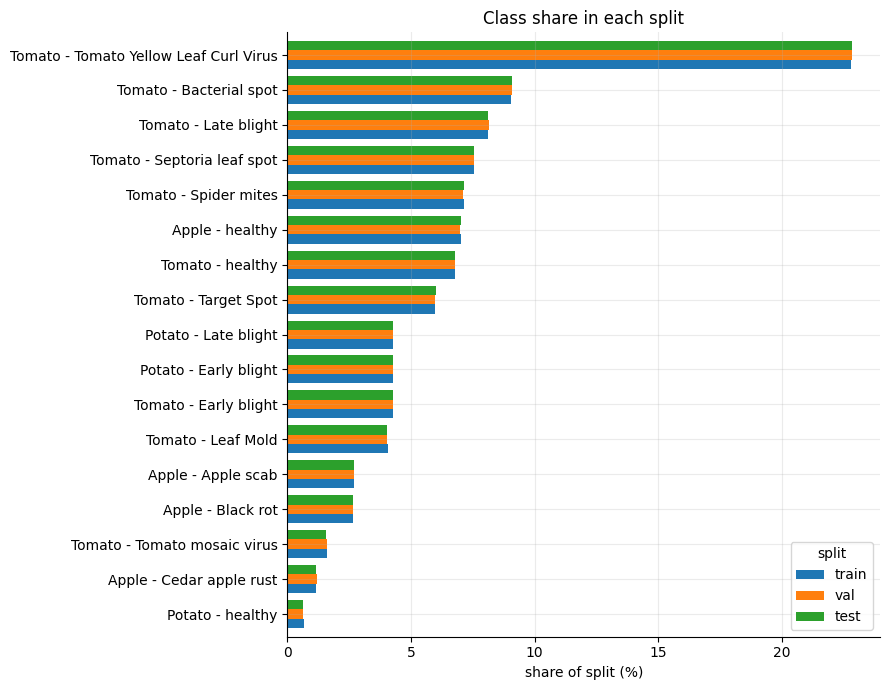

In [12]:
table = pd.crosstab(df["class_name"], df["split"])[["train", "val", "test"]]
chi2, p, dof, _ = stats.chi2_contingency(table)
print(f"Chi-square = {chi2:.3f}, dof = {dof}, p = {p:.4f}")

share = table / table.sum() * 100
ax = share.sort_values("train").plot.barh(figsize=(9, 7), width=0.8)
ax.set_xlabel("share of split (%)")
ax.set_ylabel("")
ax.set_title("Class share in each split")
save_show("split_check")

## Section 9 - Class Distribution

A classifier trained on unequal classes tends to favour the large ones, and plain accuracy can then look good even when small classes are ignored. Two numbers summarise the imbalance.

The **imbalance ratio** compares the largest and smallest class:

$$
\text{IR} = \frac{n_{\max}}{n_{\min}}.
$$

The **normalised Shannon entropy** of the class proportions $p_c = n_c/N$ measures how evenly the images are spread over the $K$ classes; it equals 1 for perfectly balanced classes and approaches 0 when one class dominates:

$$
H_{\text{norm}} = -\frac{1}{\log K}\sum_{c=1}^{K} p_c \log p_c .
$$

In [13]:
cls = df.groupby(["class_name", "crop"]).size().reset_index(name="n").sort_values("n")
p_c = cls["n"] / cls["n"].sum()
IR = cls["n"].max() / cls["n"].min()
H_norm = -(p_c * np.log(p_c)).sum() / np.log(len(cls))

print(f"Largest class : {cls.iloc[-1]['class_name']} ({cls['n'].max()} images)")
print(f"Smallest class: {cls.iloc[0]['class_name']} ({cls['n'].min()} images)")
print(f"Imbalance ratio IR = {IR:.1f}")
print(f"Normalised entropy = {H_norm:.3f}")
print(f"Healthy images: {df['is_healthy'].mean():.1%}, diseased images: {(~df['is_healthy']).mean():.1%}")

Largest class : Tomato - Tomato Yellow Leaf Curl Virus (5357 images)
Smallest class: Potato - healthy (152 images)
Imbalance ratio IR = 35.2
Normalised entropy = 0.902
Healthy images: 14.4%, diseased images: 85.6%


The bar chart shows the number of images in every class, coloured by crop. Tomato dominates the dataset, and one tomato class is far larger than the smallest potato class.

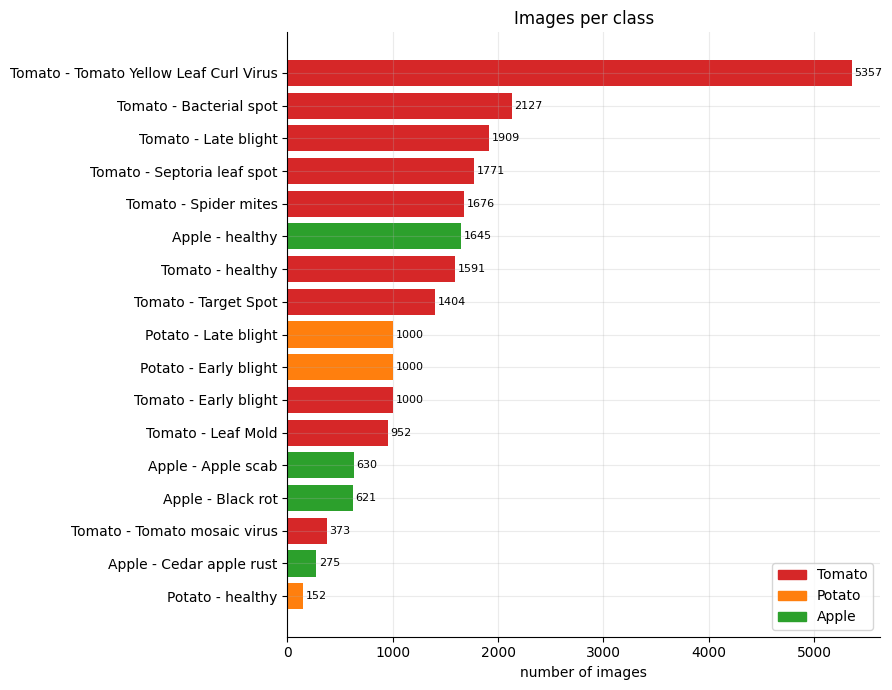

In [14]:
crop_colour = {"Tomato": "tab:red", "Potato": "tab:orange", "Apple": "tab:green"}
fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.barh(cls["class_name"], cls["n"], color=[crop_colour[c] for c in cls["crop"]])
ax.bar_label(bars, fontsize=8, padding=2)
ax.set_xlabel("number of images")
ax.set_title("Images per class")
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in crop_colour.values()]
ax.legend(handles, crop_colour.keys(), loc="lower right")
save_show("class_distribution")

Class distribution can also be viewed at the level of the other modalities: how the images divide between crops and between cause types (fungus, bacterium, virus, ...). This shows which kinds of disease the dataset represents well.

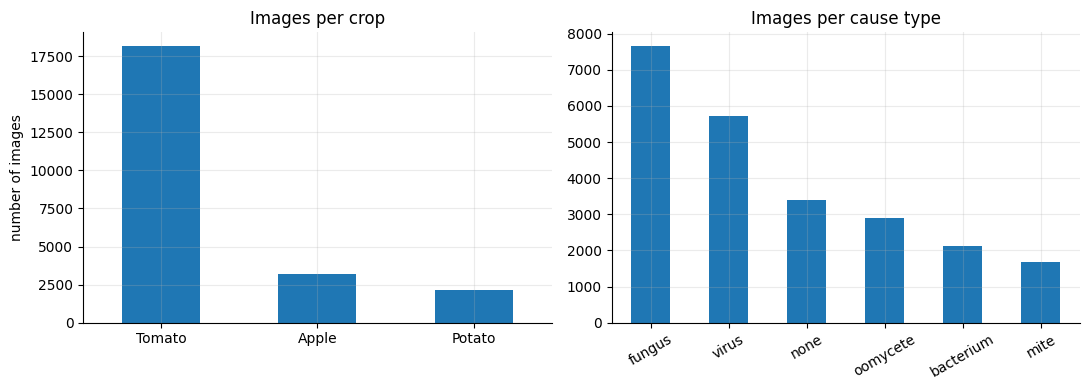

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["crop"].value_counts().plot.bar(ax=ax[0], color="tab:blue", rot=0)
ax[0].set_title("Images per crop"); ax[0].set_ylabel("number of images"); ax[0].set_xlabel("")
df["cause_type"].value_counts().plot.bar(ax=ax[1], color="tab:blue", rot=30)
ax[1].set_title("Images per cause type"); ax[1].set_xlabel("")
save_show("crop_and_cause_distribution")

**Consequence for the project.** The imbalance is large, so we report **macro-averaged** precision, recall and F1 (every class counts equally) next to accuracy, and later test a class-weighted loss.

## Section 10 - Visual Inspection of the Images

Looking at actual images shows what the models must recognise. The first figure shows one random leaf from each of the 17 classes. Many diseases look alike (brown spots, yellowing), and the healthy leaves look similar across crops.

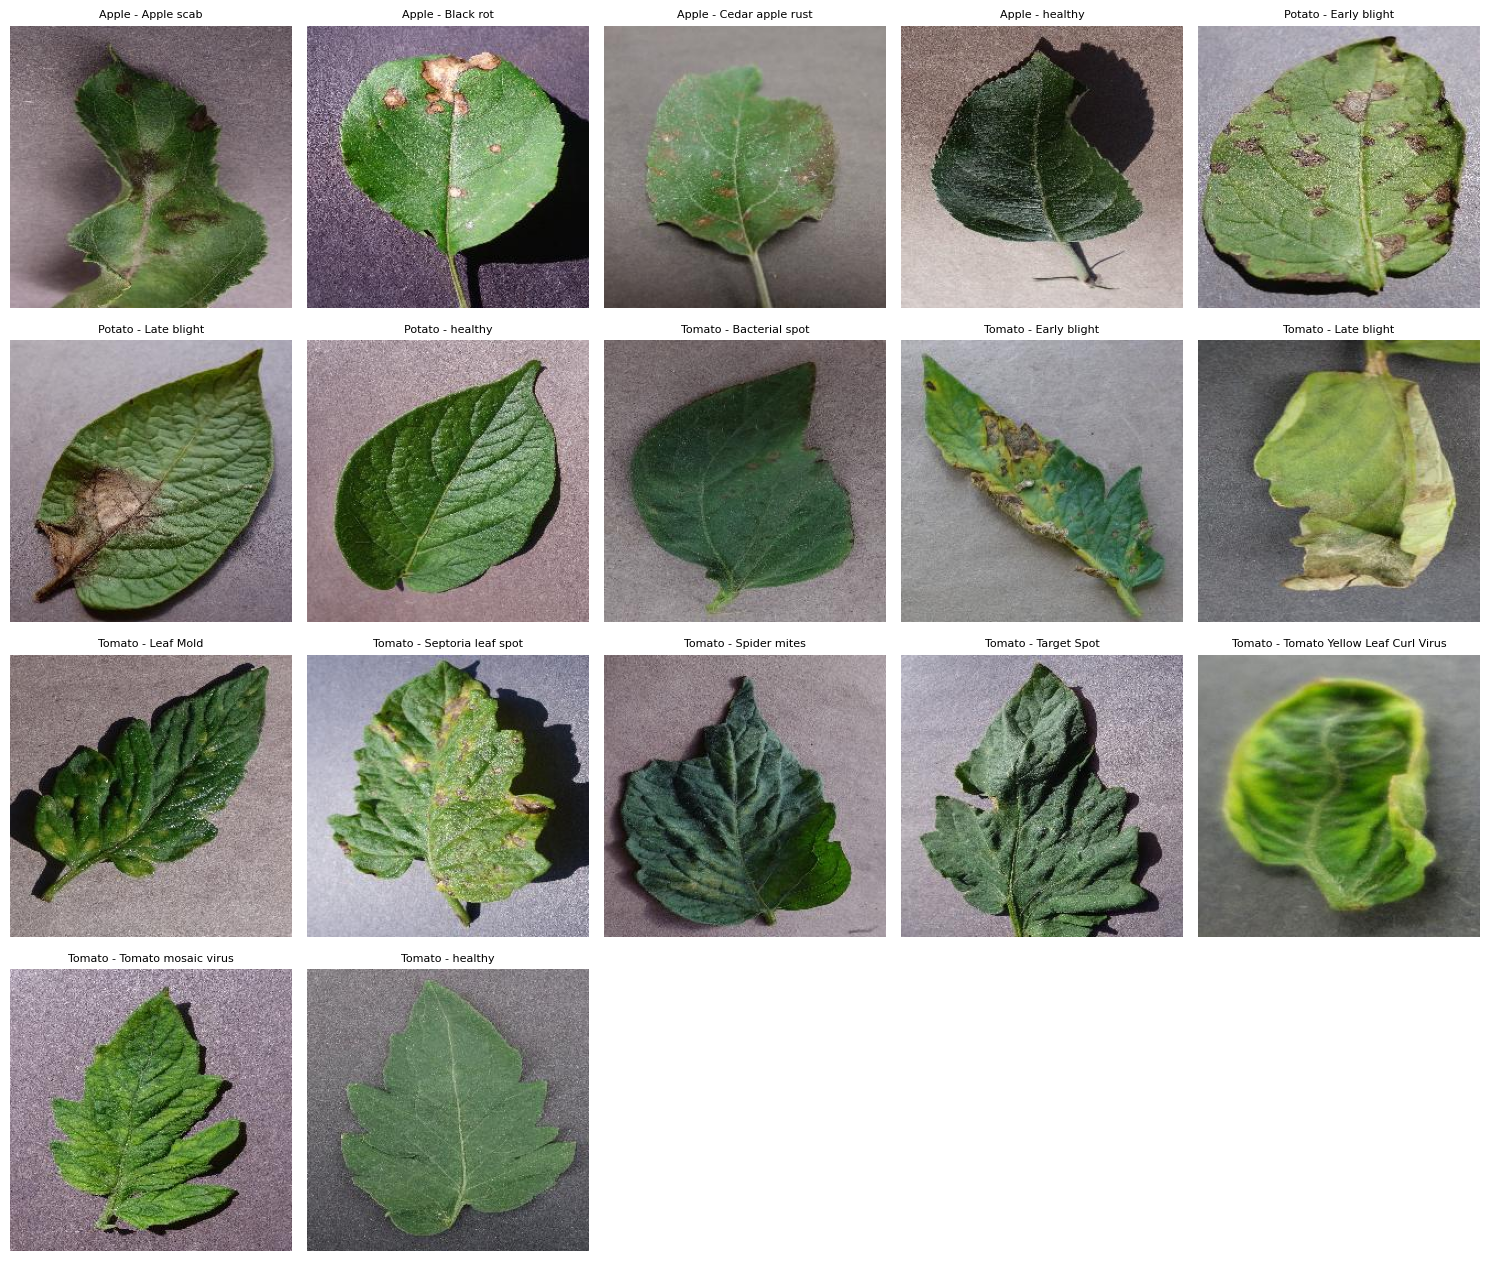

In [16]:
cols = 5
n_rows = int(np.ceil(len(class_names) / cols))
fig, axes = plt.subplots(n_rows, cols, figsize=(3 * cols, 3.2 * n_rows))
for ax in np.ravel(axes):
    ax.axis("off")
for ax, c in zip(np.ravel(axes), class_names):
    p = df[df["class_name"] == c].sample(1, random_state=1)["path"].iloc[0]
    ax.imshow(Image.open(p).convert("RGB"))
    ax.set_title(c, fontsize=8)
save_show("sample_per_class")

The second figure shows **variation inside one class**. Four random images from each of three classes: the same disease appears with different lesion sizes, leaf orientations and lighting, which is the variability a classifier has to cope with.

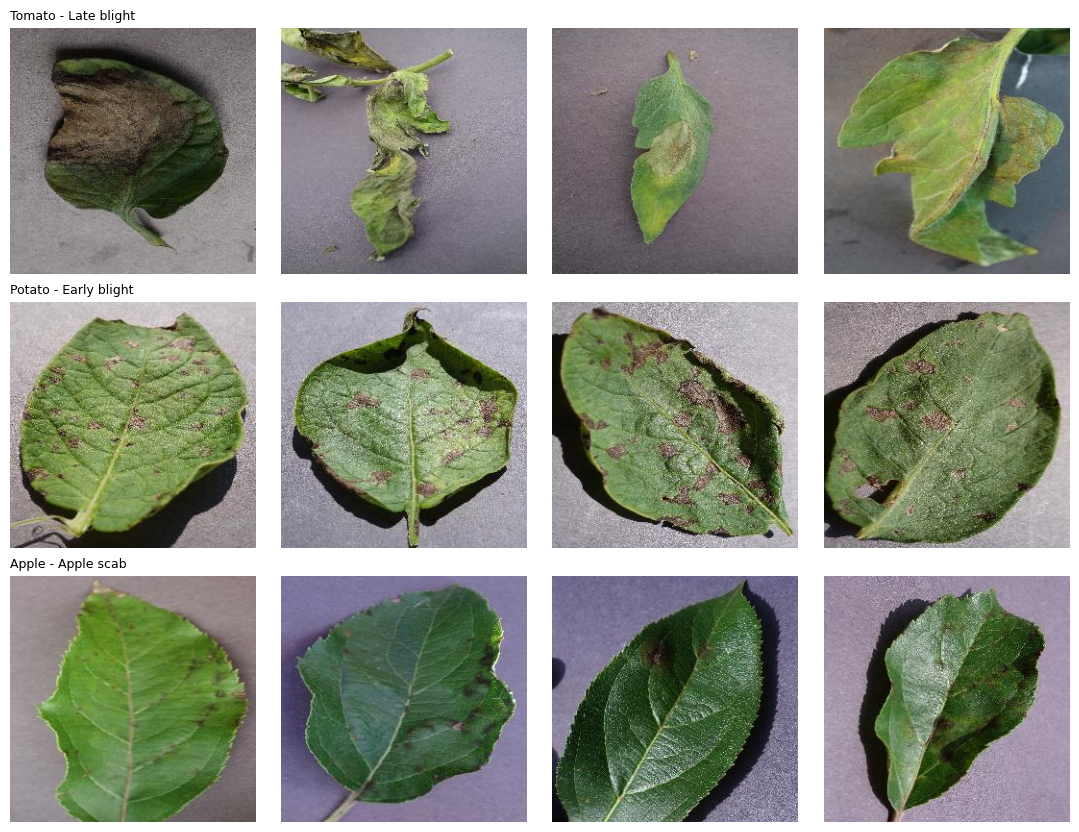

In [17]:
show = ["Tomato - Late blight", "Potato - Early blight", "Apple - Apple scab"]
show = [s for s in show if s in class_names] or class_names[:3]
fig, axes = plt.subplots(len(show), 4, figsize=(11, 2.8 * len(show)))
axes = np.atleast_2d(axes)
for r, c in enumerate(show):
    for k, p in enumerate(df[df["class_name"] == c].sample(4, random_state=3)["path"]):
        axes[r, k].imshow(Image.open(p).convert("RGB"))
        axes[r, k].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=9)
save_show("within_class_variation")

## Section 11 - Feature Distributions of the Image Modality

Simple colour features show whether classes differ in appearance. For an image $I$ of size $H\times W$ with channel $k\in\{R,G,B\}$ (values scaled to $[0,1]$) the **mean intensity** is

$$
\mu_k = \frac{1}{HW}\sum_{x=1}^{H}\sum_{y=1}^{W} I_k(x,y).
$$

After converting to HSV colour space, **brightness** is $V=\max(R,G,B)$ and **saturation** is $S=\dfrac{\max(R,G,B)-\min(R,G,B)}{\max(R,G,B)}$; we use the mean of each over the image. Finally the **colour histogram** is the proportion of pixels falling into each of $B=32$ equal intensity bins for every channel,

$$
h_k(b) = \frac{1}{HW}\,\big|\{(x,y): I_k(x,y)\in \text{bin } b\}\big|,
$$

giving a $3B = 96$-dimensional feature vector per image. These are exactly the kind of hand-crafted features used by the classical benchmark models later. They are computed for the same sample of up to 100 images per class used in Section 7.

In [18]:
BINS = 32
recs, hists = [], []
for p in sample["path"]:
    rgb = Image.open(p).convert("RGB")
    a = np.asarray(rgb, dtype=np.float32) / 255
    hsv = np.asarray(rgb.convert("HSV"), dtype=np.float32) / 255
    recs.append((a[..., 0].mean(), a[..., 1].mean(), a[..., 2].mean(), hsv[..., 2].mean(), hsv[..., 1].mean()))
    hists.append(np.concatenate([np.histogram(a[..., k], bins=BINS, range=(0, 1))[0] for k in range(3)]) / a[..., 0].size)

feat = pd.DataFrame(recs, columns=["R", "G", "B", "brightness", "saturation"])
feat[["class_name", "crop", "is_healthy"]] = sample[["class_name", "crop", "is_healthy"]]
hists = np.array(hists)
print("Feature table:", feat.shape, "| histogram matrix:", hists.shape)
display(feat.groupby("class_name")[["R", "G", "B", "brightness", "saturation"]].mean().round(3))

Feature table: (1700, 8) | histogram matrix: (1700, 96)


,R,G,B,brightness,saturation
class_name,,,,,
Apple - Apple scab,0.406,0.450,0.416,0.496,0.300
Apple - Black rot,0.464,0.493,0.449,0.532,0.268
Apple - Cedar apple rust,0.467,0.492,0.403,0.508,0.228
Apple - healthy,0.438,0.467,0.470,0.505,0.208
Potato - Early blight,0.543,0.560,0.455,0.583,0.283
Potato - Late blight,0.459,0.465,0.409,0.497,0.250
Potato - healthy,0.491,0.521,0.443,0.553,0.264
Tomato - Bacterial spot,0.398,0.421,0.364,0.440,0.224
Tomato - Early blight,0.426,0.440,0.396,0.462,0.229


The box plots show the spread of three of these features within each class. If a class's box sits clearly apart from the others, that feature helps to identify it; strong overlap means the feature alone is not enough.

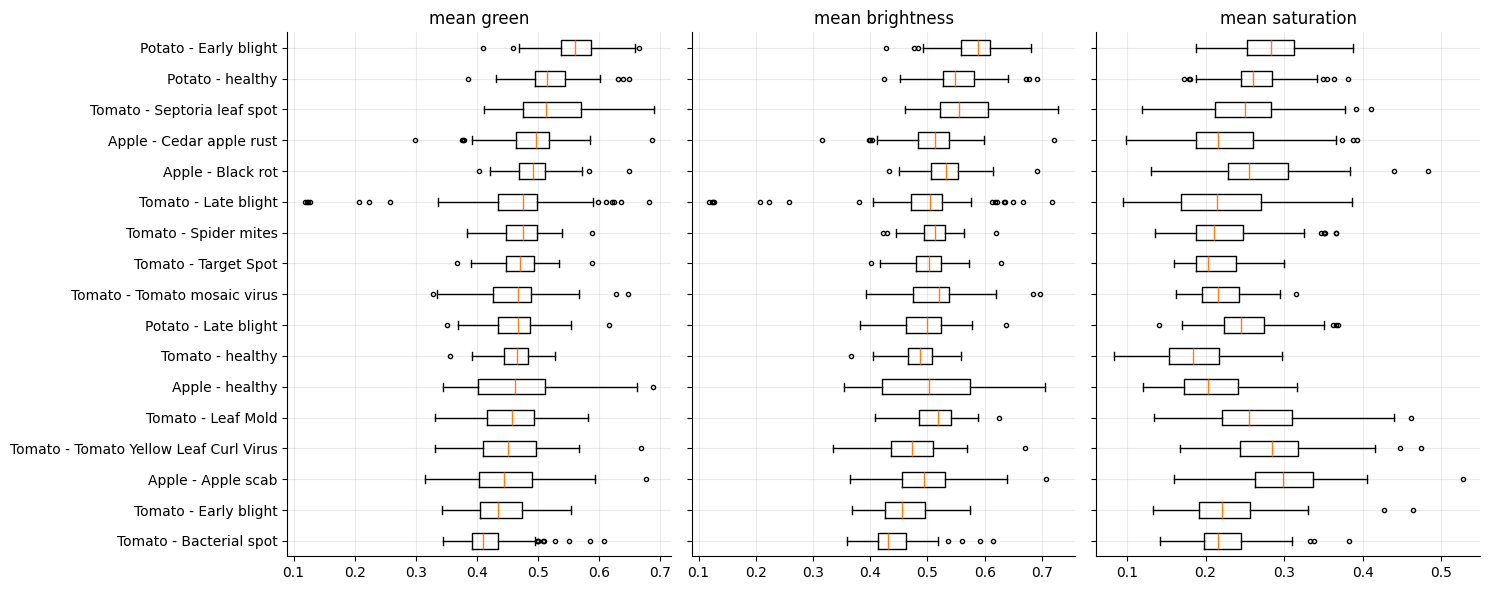

In [19]:
order = feat.groupby("class_name")["G"].median().sort_values().index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, col, title in zip(axes, ["G", "brightness", "saturation"], ["mean green", "mean brightness", "mean saturation"]):
    ax.boxplot([feat.loc[feat["class_name"] == c, col] for c in order], vert=False, flierprops={"markersize": 3})
    ax.set_yticks(range(1, len(order) + 1))
    ax.set_yticklabels(order)
    ax.set_title(title)
save_show("colour_feature_boxplots")

The histograms below show the average intensity distribution of each colour channel for every crop. They show how the crops differ in overall colour, and the shapes of these curves are the raw material for the colour-histogram features.

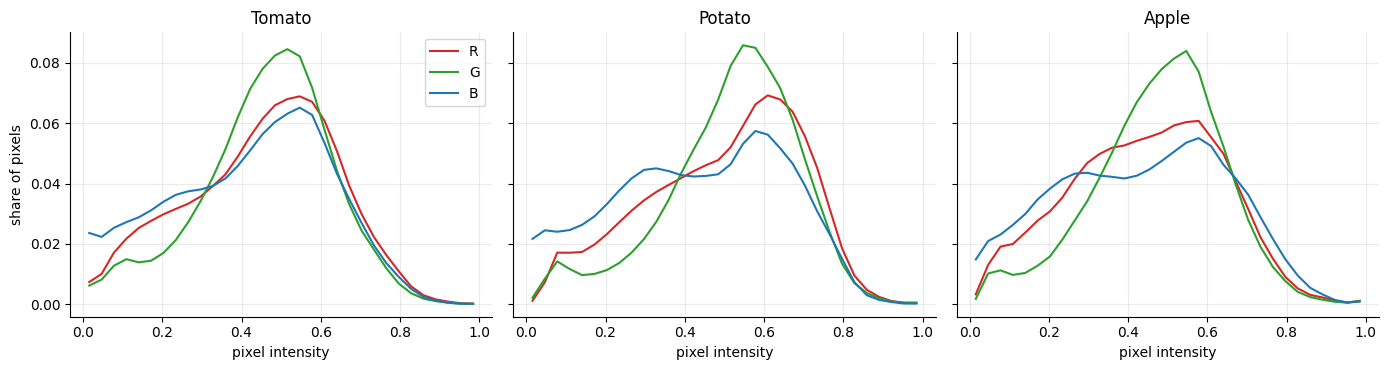

In [20]:
centres = (np.arange(BINS) + 0.5) / BINS
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, crop in zip(axes, ["Tomato", "Potato", "Apple"]):
    idx = (feat["crop"] == crop).values
    if idx.sum() == 0:
        ax.set_visible(False)
        continue
    for k, (name, colour) in enumerate(zip("RGB", ["tab:red", "tab:green", "tab:blue"])):
        ax.plot(centres, hists[idx][:, k * BINS:(k + 1) * BINS].mean(axis=0), color=colour, label=name)
    ax.set_title(crop); ax.set_xlabel("pixel intensity")
axes[0].set_ylabel("share of pixels"); axes[0].legend()
save_show("channel_histograms_by_crop")

**Statistical test.** To check whether the differences between classes are real or just noise, we use the **Kruskal-Wallis test**, a non-parametric version of one-way ANOVA that does not assume normal data. Pooling all $N$ observations and ranking them, with $R_i$ the sum of ranks and $n_i$ the size of group $i$ among $g$ groups,

$$
H = \frac{12}{N(N+1)}\sum_{i=1}^{g}\frac{R_i^{2}}{n_i} - 3(N+1).
$$

A small $p$-value says that at least one class has a different distribution of that feature.

In [21]:
rows = []
for col in ["R", "G", "B", "brightness", "saturation"]:
    H, p = stats.kruskal(*[g[col].values for _, g in feat.groupby("class_name")])
    rows.append((col, round(H, 1), p))
display(pd.DataFrame(rows, columns=["feature", "H statistic", "p-value"]))

,feature,H statistic,p-value
0,R,519.0,3.294410e-100
1,G,510.5,2.058299e-98
2,B,511.5,1.218202e-98
3,brightness,579.9,4.172572e-113
4,saturation,492.7,1.138795e-94


**How separable are the classes by colour alone?** Principal component analysis (PCA) projects the 96-dimensional histograms onto the two directions of largest variance. The directions are the eigenvectors of the covariance matrix $\Sigma$ of the standardised data, and the share of variance explained by component $j$ is $\lambda_j/\sum_i \lambda_i$. If points of one colour (crop) or marker (healthy or diseased) form clusters, colour carries information; heavy overlap shows that classes need richer features such as texture and shape.

Explained variance: [26.9 15. ] %


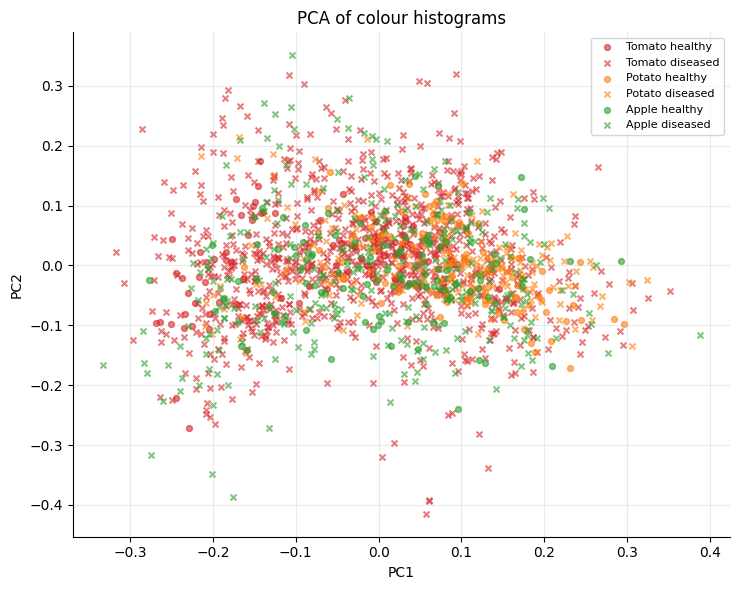

In [22]:
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(hists)
print("Explained variance:", (pca.explained_variance_ratio_ * 100).round(1), "%")

fig, ax = plt.subplots(figsize=(7.5, 6))
for crop, colour in crop_colour.items():
    for healthy, marker in [(True, "o"), (False, "x")]:
        m = ((feat["crop"] == crop) & (feat["is_healthy"] == healthy)).values
        if m.any():
            ax.scatter(pcs[m, 0], pcs[m, 1], s=18, alpha=0.6, color=colour, marker=marker,
                       label=f"{crop} {'healthy' if healthy else 'diseased'}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("PCA of colour histograms")
ax.legend(fontsize=8)
save_show("pca_colour_histograms")

## Section 12 - Analysis of the Text Modality

The text modality is analysed on its own first: how long the descriptions are and how large the vocabulary is. Because there is one description per class, these statistics are computed over the 17 class descriptions.

Descriptions: 17 | words per description: min 13, mean 21.9, max 27
Vocabulary size: 143 unique words


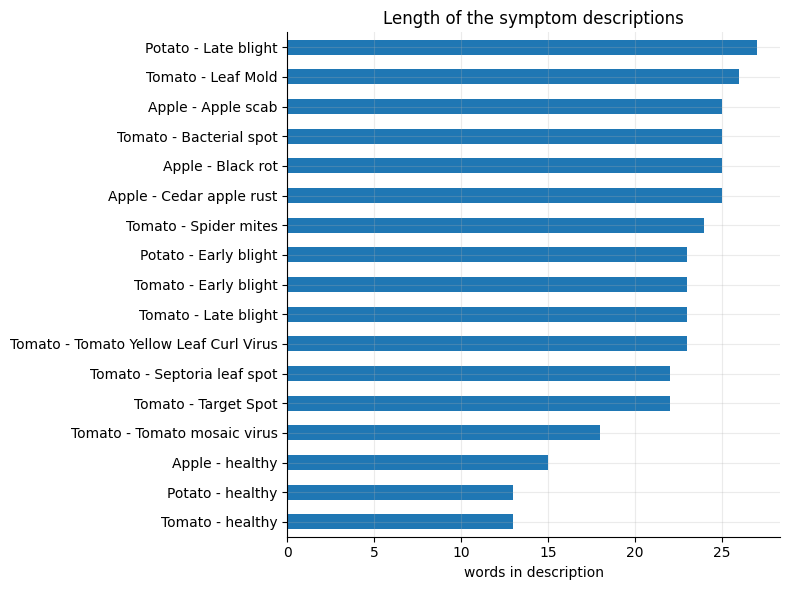

In [23]:
desc = (df.drop_duplicates("class_name").set_index("class_name")["symptom_text"].reindex(class_names))
words = desc.str.lower().str.findall(r"[a-z]+")
lens = words.str.len()
vocab = sorted({w for ws in words for w in ws})

print(f"Descriptions: {len(desc)} | words per description: min {lens.min()}, mean {lens.mean():.1f}, max {lens.max()}")
print(f"Vocabulary size: {len(vocab)} unique words")

ax = lens.sort_values().plot.barh(figsize=(8, 6), color="tab:blue")
ax.set_xlabel("words in description"); ax.set_ylabel("")
ax.set_title("Length of the symptom descriptions")
save_show("text_lengths")

**How similar are the descriptions to each other?** Each description is turned into a TF-IDF vector. For a term $t$ in description $d$, with $N$ descriptions and $\mathrm{df}(t)$ of them containing $t$, scikit-learn uses

$$
\text{tf-idf}(t,d) = \mathrm{tf}(t,d)\cdot\Big(\ln\frac{1+N}{1+\mathrm{df}(t)}+1\Big),
$$

which gives high weight to words that distinguish one description from the others. Two descriptions are compared with **cosine similarity**

$$
\cos(a,b) = \frac{a\cdot b}{\lVert a\rVert\,\lVert b\rVert}\in[0,1],
$$

where 1 means identical word usage. Classes with very similar text (for example diseases with ring-shaped brown spots) are expected to be harder to tell apart.

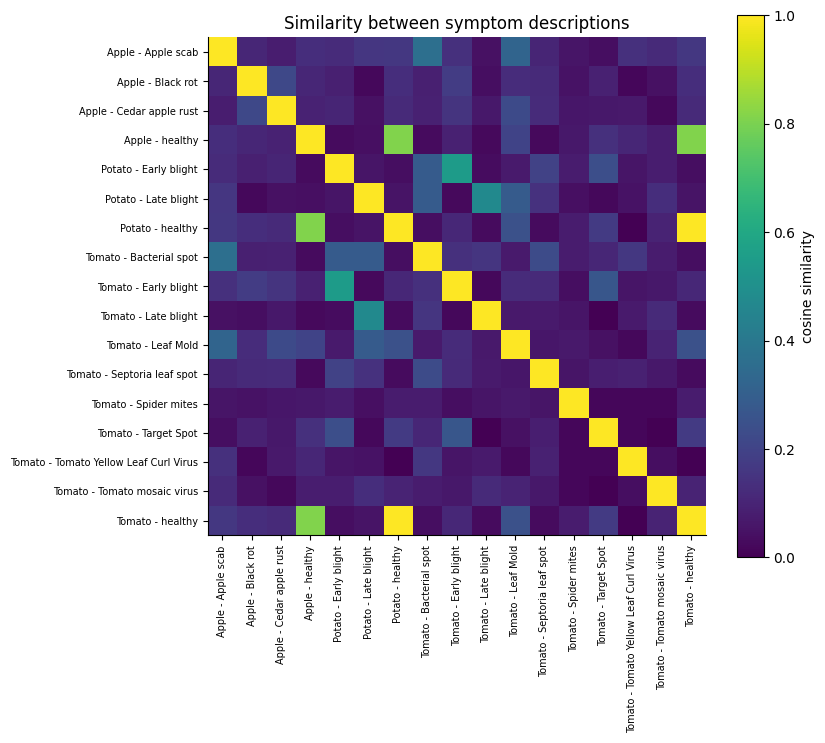

Most similar pairs of descriptions:


,class_a,class_b,text_similarity
90,Potato - healthy,Tomato - healthy,1.000
47,Apple - healthy,Potato - healthy,0.811
57,Apple - healthy,Tomato - healthy,0.811
61,Potato - Early blight,Tomato - Early blight,0.548
73,Potato - Late blight,Tomato - Late blight,0.473
6,Apple - Apple scab,Tomato - Bacterial spot,0.367
9,Apple - Apple scab,Tomato - Leaf Mold,0.321
74,Potato - Late blight,Tomato - Leaf Mold,0.289


In [24]:
tfidf = TfidfVectorizer(stop_words="english")
T = tfidf.fit_transform(desc.values)
text_sim = cosine_similarity(T)

fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(text_sim, cmap="viridis")
ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=90, fontsize=7)
ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, label="cosine similarity")
ax.set_title("Similarity between symptom descriptions")
save_show("text_similarity")

iu = np.triu_indices(len(class_names), k=1)
pairs = pd.DataFrame({"class_a": np.array(class_names)[iu[0]], "class_b": np.array(class_names)[iu[1]], "text_similarity": text_sim[iu]})
print("Most similar pairs of descriptions:")
display(pairs.sort_values("text_similarity", ascending=False).head(8).round(3))

**Reading the heat map.** The diagonal is always 1 (a description compared with itself). Descriptions of different diseases are mostly dissimilar, but the healthy classes of different crops have almost identical text, because they all describe an unblemished green leaf. This is expected: text alone cannot tell the crop apart for healthy leaves, which is one reason the crop metadata is kept as a separate modality.

## Section 13 - Relationship Between the Modalities

A useful multi-modal dataset has modalities that are related but not identical. We test whether classes that *read* alike also *look* alike. For every pair of classes we compute

* the **text similarity** from Section 12, and
* the **image similarity**: the cosine similarity between the two classes' mean colour-histogram vectors from Section 11.

The relationship is measured with **Spearman's rank correlation**, which uses only the ranks of the values and is therefore robust to non-linear relations:

$$
\rho = 1-\frac{6\sum_i d_i^{2}}{n(n^{2}-1)},
$$

where $d_i$ is the difference between the ranks of pair $i$ in the two similarity lists and $n$ is the number of class pairs. A value near 0 means the two modalities carry largely independent information (which is good for fusion), while a value near 1 would mean one modality is redundant.

Spearman rho = -0.065, p = 0.4519, over 136 class pairs


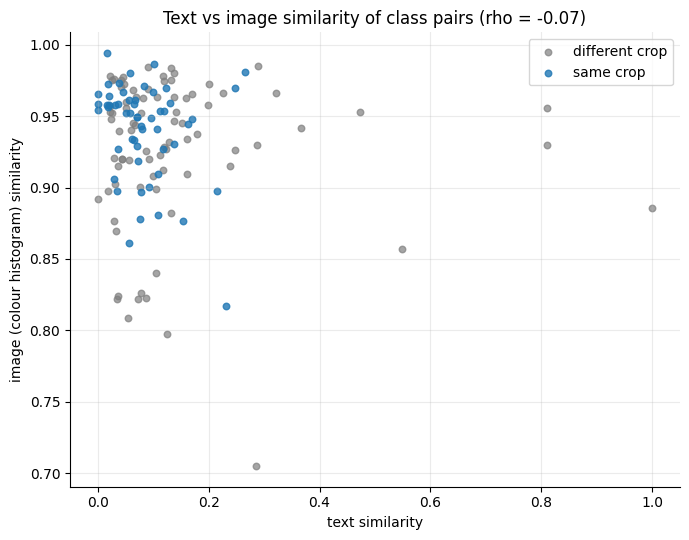

In [25]:
class_hist = np.array([hists[(feat["class_name"] == c).values].mean(axis=0) for c in class_names])
img_sim = cosine_similarity(class_hist)

x, y = text_sim[iu], img_sim[iu]
same_crop = np.array([c1.split(" - ")[0] == c2.split(" - ")[0] for c1, c2 in zip(pairs["class_a"], pairs["class_b"])])
rho, p = stats.spearmanr(x, y)
print(f"Spearman rho = {rho:.3f}, p = {p:.4f}, over {len(x)} class pairs")

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(x[~same_crop], y[~same_crop], s=22, alpha=0.7, color="tab:gray", label="different crop")
ax.scatter(x[same_crop], y[same_crop], s=22, alpha=0.8, color="tab:blue", label="same crop")
ax.set_xlabel("text similarity"); ax.set_ylabel("image (colour histogram) similarity")
ax.set_title(f"Text vs image similarity of class pairs (rho = {rho:.2f})")
ax.legend()
save_show("text_vs_image_similarity")

## Section 14 - Summary of the Dataset

The final cell collects the main properties in one table and saves it. The points below should be discussed in the report.

* **Modalities:** image (unstructured), text (symptom description) and tabular metadata (crop, cause type, pathogen).
* **Class imbalance** (Section 9) calls for macro-averaged metrics and possibly class weights.
* **Uniform image format** (Section 7): every image has the same size and colour mode, so preprocessing is simple.
* **Class overlap:** colour statistics differ significantly between classes (Kruskal-Wallis), but the boxes and the PCA plot overlap strongly, so colour alone is not enough and shape/texture features are needed.
* **Text modality:** descriptions of different diseases share vocabulary (spots, yellow halo, concentric rings), mirroring visually similar diseases.
* **Limitations:** images show a single leaf on a plain background taken under controlled conditions, so accuracy on PlantVillage is expected to be much higher than on field photographs (Mohanty et al. report about 31 % on images from other sources). The text and metadata are class-level, not per-image. Several photographs can show the same physical leaf, so a purely random split may place near-duplicates in different sets.

In [26]:
summary = pd.DataFrame({
    "property": ["images", "classes", "crops", "modalities", "image size", "split (train/val/test)",
                 "largest class", "smallest class", "imbalance ratio", "normalised entropy",
                 "text descriptions", "text vocabulary", "text-image similarity (Spearman rho)"],
    "value": [f"{len(df):,}", df["label"].nunique(), df["crop"].nunique(), "image, text, tabular",
              " x ".join(map(str, props.groupby(['width', 'height']).size().idxmax())),
              " / ".join(str((df["split"] == s).sum()) for s in ["train", "val", "test"]),
              f"{cls.iloc[-1]['class_name']} ({cls['n'].max()})", f"{cls.iloc[0]['class_name']} ({cls['n'].min()})",
              f"{IR:.1f}", f"{H_norm:.3f}", len(desc), len(vocab), f"{rho:.3f}"],
})
summary.to_csv(RESULTS / "dataset_summary.csv", index=False)
display(summary)
print("\nFigures and tables saved to:", RESULTS)

,property,value
0,images,"23,483"
1,classes,17
2,crops,3
3,modalities,"image, text, tabular"
4,image size,256 x 256
5,split (train/val/test),18786 / 2348 / 2349
6,largest class,Tomato - Tomato Yellow Leaf Curl Virus (5357)
7,smallest class,Potato - healthy (152)
8,imbalance ratio,35.2
9,normalised entropy,0.902



Figures and tables saved to: /Users/sabyasachi/plant_disease_based_classification/results/dataset_analysis
